In [1]:
from google.colab import drive
import os

drive.mount('/content/drive')
base = "/content/drive/MyDrive/UTokyo/Proteome"
OUTPUT_DIR = os.path.join(base, "Publication")

Mounted at /content/drive


# Cell 0 - Settings and shared functions

In [4]:
# ===================== Cell 0 — shared constants, helpers and orthogroup selection =====================
import os, re, glob, hashlib
import pandas as pd

# Reuses `base` and `OUTPUT_DIR` from the notebook's first cell (Drive already mounted).
try:
    base, OUTPUT_DIR
except NameError:                       # fallback if this notebook is run on its own
    from google.colab import drive
    drive.mount('/content/drive')
    base = '/content/drive/MyDrive/UTokyo/Proteome'
    OUTPUT_DIR = os.path.join(base, 'Publication')

# ---- Inputs ----------------------------------------------------------------------
ORTHO_ROOT      = os.path.join(base, '9_Ortholog_analysis')
OF_RESULTS      = os.path.join(ORTHO_ROOT, 'Pro_OF_dendroblast')          # OrthoFinder results
ORTHOGROUPS_TSV = os.path.join(OF_RESULTS, 'Orthogroups', 'Orthogroups.tsv')
OG_SEQ_DIR      = os.path.join(OF_RESULTS, 'Orthogroup_Sequences')   # optional; not needed
OF_WORKDIR      = os.path.join(OF_RESULTS, 'WorkingDirectory')        # SpeciesIDs.txt, SequenceIDs.txt, Species*.fa
SPECIES_TREE    = os.path.join(OF_RESULTS, 'Species_Tree', 'SpeciesTree_Bmin_rooted.txt')  # same tree as Panel C
DATA_PRE        = os.path.join(base, 'Publication', 'data_pre')
TABLE_S1        = os.path.join(DATA_PRE, 'TableS1_secretome_associated_orthogroups.tsv')

STRAINS = ['Spil', 'Snat', 'Stri', 'Slin', 'Snec', 'Smic', 'Bmin']   # fixed phylogenetic order (display keys)
FILE_KEY = {s: s for s in STRAINS}; FILE_KEY['Smic'] = 'Smic_jgi'      # master key used in folders/files

# Final SP+ / SP- secretome FASTAs (pipeline outputs)
SEC_ROOT = os.path.join(base, 'Prediction_vs_Detection')
def sp_pos_fasta(s): return os.path.join(SEC_ROOT, FILE_KEY[s], '09_final', f'{FILE_KEY[s]}_SP_pos_secretome_final.faa')
def sp_neg_fasta(s): return os.path.join(SEC_ROOT, FILE_KEY[s], '09_final', f'{FILE_KEY[s]}_SP_neg_secretome_final.faa')
SECRETOME_FASTA = {s: {'SP+': sp_pos_fasta(s), 'SP-': sp_neg_fasta(s)} for s in STRAINS}

# Prediction-detection overlap outputs (Block 2-2); the folder name contains 'Overlap'
OVERLAP_DIRS = [os.path.join(base, 'MS_data', '*Overlap*'),
                os.path.join(base, 'Prediction_vs_Detection', 'MS_data', '*Overlap*')]
MS_STRAINS = ['Smic', 'Snat', 'Bmin']                                  # strains with exoproteome data

# ---- Outputs ----------------------------------------------------------------------
WORK_DIR = os.path.join(ORTHO_ROOT, 'secretion_evolution')     # alignments and gene trees
FIG_DIR  = os.path.join(OUTPUT_DIR, 'figures_pre')
DATA_DIR = DATA_PRE
for d in (WORK_DIR, FIG_DIR, DATA_DIR):
    os.makedirs(d, exist_ok=True)

GAIN_COST_WEIGHTED = 2   # weighted (Sankoff) model: gaining an SP costs 2 losses

# ---- Fixed visual conventions -----------------------------------------------------
CLADE_COLOR = {'Symbiodinium': '#2C7A7B', 'Breviolum': '#7C4A6E'}
STRAIN_CLADE = {s: ('Breviolum' if s == 'Bmin' else 'Symbiodinium') for s in STRAINS}

# ---- Rooting mode -------------------------------------------------------------------
# False (first submission): seven species; root on B. minutum if monophyletic, else midpoint.
# True  (revision only):    trees with a P. glacialis outgroup, built in Appendix B3.
USE_OUTGROUP = False

# ---- Appendix B only: external outgroup (Polarella glacialis) ---------------------------
OUTGROUP_NAME = 'Pgla'
OUTGROUP_LABEL = 'P. glacialis'
CLADE_COLOR['Outgroup'] = '#555555'
STRAIN_CLADE[OUTGROUP_NAME] = 'Outgroup'
OG_DIR = os.path.join(WORK_DIR, 'with_outgroup')                 # outgroup trees live here, never in WORK_DIR
TIPS_WITH_OUTGROUP = os.path.join(OG_DIR, 'secretion_evolution_tips_with_outgroup.tsv')
# Outgroup proteome on Drive (Polarella glacialis, Stephens et al. 2020, BMC Biology 18:56) — EDIT
OUTGROUP_FAA = os.path.join(ORTHO_ROOT, 'outgroup', 'Polarella_glacialis_CCMP1383.faa')
OUTGROUP_HITS_FAA = os.path.join(WORK_DIR, 'outgroup_hits.faa')
OUTGROUP_HITS_TSV = os.path.join(WORK_DIR, 'outgroup_hits.tsv')
# Secretome-pipeline output for P. glacialis (whole proteome or hits only), from the HPC — EDIT names if different
OUTGROUP_PIPE_DIR = os.path.join(WORK_DIR, 'outgroup_pipeline')
OUTGROUP_SP_POS = os.path.join(OUTGROUP_PIPE_DIR, f'{OUTGROUP_NAME}_SP_pos_secretome_final.faa')
OUTGROUP_SP_NEG = os.path.join(OUTGROUP_PIPE_DIR, f'{OUTGROUP_NAME}_SP_neg_secretome_final.faa')
OUTGROUP_EVALUE, OUTGROUP_MIN_SCOV = 1e-10, 0.5   # hit E-value; hit must cover >=50% of its own length
OUTGROUP_FALLBACK_BEST_HIT = True                  # OGs without a reciprocal best hit use their best hit

TREE_DIR = OG_DIR if USE_OUTGROUP else WORK_DIR    # where Cells 4-5 read trees and alignments
os.makedirs(OG_DIR, exist_ok=True)
SECRETED_COLOR = '#4C9F70'      # "Secretome only" colour
NONSEC_COLOR   = '#D9D9D9'      # "Non-secretome only" colour
GAIN_COLOR     = '#4C9F70'
LOSS_COLOR     = '#B0492E'
SPECIES_KEYWORDS = {'Spil': 'pilosum', 'Snat': 'natans', 'Stri': 'tridacnidorum',
                    'Slin': 'linucheae', 'Snec': 'necroappetens',
                    'Smic': 'microadriaticum', 'Bmin': 'minutum'}

# If an OrthoFinder species label (Orthogroups.tsv column / species-tree tip) cannot be
# recognised automatically, map it here, e.g. {'symbB.v1.2.augustus.prot': 'Bmin'}
LABEL_OVERRIDES = {}

def strain_from_label(label):
    """Map an OrthoFinder species/column label to a strain key."""
    if label in LABEL_OVERRIDES:
        return LABEL_OVERRIDES[label]
    low = label.lower()
    hits = [s for s in STRAINS if s.lower() in low or SPECIES_KEYWORDS[s] in low]
    if len(hits) != 1:
        raise ValueError(f'Cannot map "{label}" to one strain (hits: {hits}). '
                         'Add an explicit mapping in Cell 0.')
    return hits[0]

def seq_md5(seq):
    return hashlib.md5(str(seq).upper().replace('*', '').replace(' ', '').encode()).hexdigest()

BMIN_RE = re.compile(r'(symbB\.v1\.2\.\d{6}\.t\d+)')

def norm_id(strain, pid):
    """Protein-ID normalisation (same logic as Block A). `strain` is a display key."""
    if not isinstance(pid, str):
        return pid
    pid = pid.strip().split()[0]
    if strain == 'Smic':                     # target: jgi|Symmic1|NUM_rnaNUM
        if '|' in pid and '_' not in pid:
            head, tail = pid.rsplit('|', 1)
            return f'{head}_{tail}'
        if '_' in pid:
            parts = pid.split('_', 3)
            if len(parts) == 4:
                return '|'.join(parts[:3]) + '_' + parts[3]
        return pid
    if strain == 'Bmin':
        m = BMIN_RE.search(pid)
        return m.group(1) if m else pid.split('|')[0]
    return pid

def read_table(path):
    return pd.read_excel(path) if path.endswith(('.xlsx', '.xls')) else pd.read_csv(path, sep='\t')

def status_col(df, s):
    """Status column for strain s in Table S1 ('Smic_status' or 'Smic_jgi_status')."""
    for c in (f'{s}_status', f'{FILE_KEY[s]}_status'):
        if c in df.columns:
            return c
    raise KeyError(f'No status column for {s} in Table S1')

def save_fig(fig, stem):
    for ext in ('pdf', 'svg', 'png'):
        fig.savefig(f'{FIG_DIR}/{stem}.{ext}', dpi=600, bbox_inches='tight')
    print('Saved', f'{FIG_DIR}/{stem}.{{pdf,svg,png}}')

# ---- Parsimony (Sankoff; Fitch = equal costs) on Bio.Phylo trees --------------------
INF = float('inf')

def sankoff(tree, tip_state, gain_cost):
    """Binary character (0/1) on a rooted tree. Returns (min cost, reconstructions),
    one reconstruction per optimal root state: (root_state, node_states, events).
    A tip state of None is treated as unknown and can take either state at no cost."""
    cost = lambda a, b: 0 if a == b else (gain_cost if b == 1 else 1)
    C = {}
    for c in tree.find_clades(order='postorder'):
        if c.is_terminal():
            st = tip_state[c.name]                     # None = unknown (missing data)
            C[id(c)] = [0 if st is None or st == s else INF for s in (0, 1)]
        else:
            C[id(c)] = [sum(min(C[id(ch)][k] + cost(s, k) for k in (0, 1)) for ch in c.clades)
                        for s in (0, 1)]
    rc = C[id(tree.root)]
    best = min(rc)
    recs = []
    for r in [s for s in (0, 1) if rc[s] - best < 1e-9]:
        S, ev = {id(tree.root): r}, []
        for c in tree.find_clades(order='preorder'):
            for ch in c.clades:
                opts = [C[id(ch)][k] + cost(S[id(c)], k) for k in (0, 1)]
                m = min(opts)
                ks = [k for k in (0, 1) if opts[k] - m < 1e-9]
                S[id(ch)] = S[id(c)] if S[id(c)] in ks else ks[0]   # delay changes on ties
                if S[id(ch)] != S[id(c)]:
                    ev.append((ch, 'gain' if S[id(ch)] == 1 else 'loss'))
        recs.append((r, S, ev))
    return best, recs

def count_events(ev):
    return sum(e == 'gain' for _, e in ev), sum(e == 'loss' for _, e in ev)

def node_support(c):
    """UFBoot support of an internal node (IQ-TREE writes it as the node label)."""
    if c.confidence is not None:
        return float(c.confidence)
    try:
        return float(str(c.name).split('/')[-1])
    except (TypeError, ValueError):
        return -1.0

def split_root_branch(tree):
    """After outgroup rooting, Biopython puts the whole root edge on one side (the other is 0).
    Split the edge evenly between the two root children; the total distance is unchanged."""
    kids = tree.root.clades
    if len(kids) == 2:
        total = (kids[0].branch_length or 0.0) + (kids[1].branch_length or 0.0)
        kids[0].branch_length = kids[1].branch_length = total / 2
    return tree

# ---- Font: DejaVu Sans ships with matplotlib, so no 'findfont' warnings on Colab ----
import logging
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
FONT = ['DejaVu Sans']

print('path check:')
for label, p_ in [('Orthogroups.tsv', ORTHOGROUPS_TSV), ('WorkingDirectory', OF_WORKDIR),
                  ('Species tree', SPECIES_TREE), ('Table S1', TABLE_S1)]:
    print(f"  {'OK  ' if os.path.exists(p_) else 'MISS'} {label}")
for s_ in STRAINS:
    print(f"  {s_:5s} {'OK' if os.path.exists(sp_pos_fasta(s_)) else 'MISS'} SP+  "
          f"{'OK' if os.path.exists(sp_neg_fasta(s_)) else 'MISS'} SP-")
print('Rooting mode:', 'P. glacialis outgroup (Appendix B trees)' if USE_OUTGROUP
      else 'seven species (B. minutum / midpoint)', '| trees read from', TREE_DIR)
print('overlap dirs:', [d for pat in OVERLAP_DIRS for d in glob.glob(pat)] or 'none found')

# ---- Orthogroups for the main and supplementary gene-tree figures -------------------
# Main figure: enzyme orthogroups of the final table (CAZymes, δ-CA, peptidases), in panel order.
# Supplementary: enriched-Pfam orthogroups chosen by the rule below, preferring OGs without exoproteome detection.
import gzip, urllib.request

MAIN = {   # orthogroup: (label, main Pfam)
    'OG0007569': ('GH29 α-L-fucosidase',        'PF01120'),
    'OG0001495': ('GH7',                        'PF00840'),
    'OG0001376': ('GH7 + CBM1',                 'PF00840'),
    'OG0004349': ('α-Amylase',                  'PF00128'),
    'OG0001619': ('α-Amylase + ILEI',           'PF00128'),
    'OG0026291': ('GH2 TIM barrel',             'PF02836'),
    'OG0000735': ('GH catalytic core',          'PF11790'),
    'OG0010713': ('S28 serine peptidase',       'PF05577'),
    'OG0004769': ('S28 serine peptidase',       'PF05577'),
    'OG0025622': ('C1 + I29 peptidase',         'PF00112'),
    'OG0000328': ('δ-Carbonic anhydrase',       'PF10563'),
    'OG0002581': ('δ-Carbonic anhydrase',       'PF10563'),
}
SUPP_FIXED = {     # kept from the previous analysis (trees already built)
    'OG0001942': ('GH16',                       'PF26113'),
    'OG0009651': ('C1 papain-family peptidase', 'PF00112'),
    'OG0000462': ('A1 aspartyl peptidase',      'PF00026'),
    'OG0002433': ('Sulfatase',                  'PF00884'),
}
SUPP_BY_PFAM = {   # one orthogroup is picked per Pfam by the rule below
    'PF05050': 'FkbM methyltransferase',
}
ADD_OTHER_CAZYMES = True     # also add one orthogroup per other enriched CAZy family
CAZY_GROUPS = ('GH', 'GT', 'CBM', 'PL', 'CE')   # add 'GT' to include glycosyltransferases (mostly Golgi-resident)
FAMILY_OVERRIDES = {'PF00150': 'GH5'}     # Pfam entries whose name lacks the CAZy family number
EXCLUDE = set()              # orthogroups to drop after looking at the printout, e.g. {'OG0012345'}
MIN_PROTEINS = 4             # smallest orthogroup worth a tree

s1_sel = read_table(TABLE_S1)
s1_sel['enr'] = s1_sel.Enriched_Pfams.fillna('').astype(str).str.split(',').apply(
    lambda l: {p.strip() for p in l if p.strip()})
s1_sel['detected'] = s1_sel.N_overlap_proteins.fillna(0) > 0
info = s1_sel.set_index('orthogroup')
missing_main = [og for og in MAIN if og not in info.index]
if missing_main:
    print('WARNING: main-figure OGs not in Table S1:', missing_main)
taken = set(MAIN) | set(SUPP_FIXED)

def pick(pfam):
    """Selection rule: enriched Pfam present; >= MIN_PROTEINS proteins; both SP+ and non-SP+ members
    (otherwise no change is possible); not yet used. Ranked: not detected first, then predicted secreted
    members in the most species, then fewer proteins (lower copy number), then more secreted proteins."""
    c = s1_sel[s1_sel.enr.apply(lambda e: pfam in e) & ~s1_sel.orthogroup.isin(taken | EXCLUDE)
               & (s1_sel.N_proteins >= MIN_PROTEINS) & (s1_sel.N_SP_plus > 0)
               & (s1_sel.N_proteins > s1_sel.N_SP_plus)]
    if c.empty:
        return None
    return c.sort_values(['detected', 'N_strains_secreted', 'N_proteins', 'N_secreted'],
                         ascending=[True, False, True, False]).iloc[0]

# Pfam names (to assign CAZy families)
PFAM_CLANS = '/content/Pfam-A.clans.tsv.gz'
if not os.path.exists(PFAM_CLANS):
    urllib.request.urlretrieve('https://ftp.ebi.ac.uk/pub/databases/Pfam/current_release/Pfam-A.clans.tsv.gz', PFAM_CLANS)
pf_names = pd.read_csv(PFAM_CLANS, sep='\t', header=None, names=['acc', 'clan', 'clan_id', 'id', 'desc'])
pf_id = dict(zip(pf_names.acc, pf_names.id))

def cazy_family(p):
    """CAZy family from the Pfam name (e.g. Glyco_hydro_3_C -> GH3), or None if it has no family number."""
    if p in FAMILY_OVERRIDES:
        return FAMILY_OVERRIDES[p]
    i = str(pf_id.get(p, ''))
    for pat, grp in ((r'^(?:Glyco_hydro|GH)_?(\d+)', 'GH'),
                     (r'^(?:Glyco_transf|Glycos_transf|Glyco_tran|Gly_transf)_?(\d+)', 'GT'),
                     (r'^CBM_?(\d+)', 'CBM'), (r'^(?:Polysacc_lyase|PL)_?(\d+)', 'PL'), (r'^CE_?(\d+)', 'CE')):
        m = re.match(pat, i)
        if m:
            return grp + m.group(1)
    return None

supp = dict(SUPP_FIXED)
for p, lab in SUPP_BY_PFAM.items():
    r = pick(p)
    if r is None:
        print(f'  no suitable orthogroup for {p} ({lab})'); continue
    supp[r.orthogroup] = (lab, p); taken.add(r.orthogroup)

n_prot = lambda og: int(info.N_proteins.get(og, 0))
if ADD_OTHER_CAZYMES:
    # families already represented by an analysable main/supplementary OG are skipped
    fam_done = {cazy_family(p) for og in taken if n_prot(og) >= 3 for p in info.enr.get(og, set())} - {None}
    fam_pfams = {}
    for p in sorted(set().union(*s1_sel.enr)):
        f = cazy_family(p)
        if f and f.startswith(CAZY_GROUPS) and f not in fam_done:
            fam_pfams.setdefault(f, []).append(p)
    fam_key = lambda f: (re.sub(r'\d', '', f), int(re.sub(r'\D', '', f)))
    for f in sorted(fam_pfams, key=fam_key):
        if f in fam_done:
            continue
        cands = [r for r in (pick(p) for p in fam_pfams[f]) if r is not None]
        if not cands:
            continue
        r = sorted(cands, key=lambda r: (r.detected, -r.N_strains_secreted, r.N_proteins, -r.N_secreted))[0]
        supp[r.orthogroup] = (f, next(p for p in fam_pfams[f] if p in r.enr)); taken.add(r.orthogroup)
        fam_done |= {cazy_family(q) for q in r.enr} - {None}   # one OG can cover several families

SELECTED = {og: (lab, p, True) for og, (lab, p) in MAIN.items()}
SELECTED.update({og: (lab, p, False) for og, (lab, p) in supp.items() if og not in EXCLUDE})

TOO_SMALL = {og: n_prot(og) for og in SELECTED if n_prot(og) < 3}
if TOO_SMALL:      # a gene tree needs at least three sequences
    print('Not analysed (fewer than 3 proteins, no tree possible):',
          {og: f'{SELECTED[og][0]}, {n} proteins' for og, n in TOO_SMALL.items()})
    SELECTED = {og: v for og, v in SELECTED.items() if og not in TOO_SMALL}

show = pd.DataFrame([dict(panel='main' if v[2] else 'supp', orthogroup=og, label=v[0], pfam=v[1],
                          pfam_name=pf_id.get(v[1], ''),
                          n_proteins=info.N_proteins.get(og), species_secreted=info.N_strains_secreted.get(og),
                          detected=bool(info.detected.get(og, False)))
                     for og, v in SELECTED.items()])
print(show.to_string(index=False))
print(f'\n{sum(v[2] for v in SELECTED.values())} main + {sum(not v[2] for v in SELECTED.values())} supplementary '
      f'orthogroups; {int(show.n_proteins.fillna(0).sum())} proteins in total')

path check:
  OK   Orthogroups.tsv
  OK   WorkingDirectory
  OK   Species tree
  OK   Table S1
  Spil  OK SP+  OK SP-
  Snat  OK SP+  OK SP-
  Stri  OK SP+  OK SP-
  Slin  OK SP+  OK SP-
  Snec  OK SP+  OK SP-
  Smic  OK SP+  OK SP-
  Bmin  OK SP+  OK SP-
Rooting mode: seven species (B. minutum / midpoint) | trees read from /content/drive/MyDrive/UTokyo/Proteome/9_Ortholog_analysis/secretion_evolution
overlap dirs: ['/content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/*Overlap*']
Not analysed (fewer than 3 proteins, no tree possible): {'OG0026291': 'GH2 TIM barrel, 2 proteins', 'OG0025622': 'C1 + I29 peptidase, 2 proteins'}
panel orthogroup                      label    pfam          pfam_name  n_proteins  species_secreted  detected
 main  OG0007569        GH29 α-L-fucosidase PF01120      Alpha_L_fucos           9                 7      True
 main  OG0001495                        GH7 PF00840      Glyco_hydro_7          19                 5      True
 main  OG0001376

# Cell 1 - Install tools

In [5]:
# ===================== Cell 1 — install MAFFT, ClipKIT, IQ-TREE 3 (after each runtime restart) =====================
import subprocess, glob, json, urllib.request

def sh(cmd):
    subprocess.run(cmd, shell=True, check=True)

def github_asset(repo, pattern):
    """Download URL of the latest release asset whose name matches `pattern`."""
    rel = json.load(urllib.request.urlopen(f'https://api.github.com/repos/{repo}/releases/latest'))
    for a_ in rel['assets']:
        if re.search(pattern, a_['name']):
            return a_['browser_download_url']
    raise RuntimeError(f'No asset matching {pattern} in {repo}: {[a_["name"] for a_ in rel["assets"]]}')

sh('apt-get -qq install -y mafft > /dev/null')
sh('pip -q install biopython clipkit')
if not glob.glob('/content/iqtree3/**/bin/iqtree3', recursive=True):
    url = github_asset('iqtree/iqtree3', r'Linux-intel\.tar\.gz$')
    sh(f'wget -q {url} -O /content/iqtree3.tgz && mkdir -p /content/iqtree3 && tar -xzf /content/iqtree3.tgz -C /content/iqtree3')
IQTREE = glob.glob('/content/iqtree3/**/bin/iqtree3', recursive=True)[0]
for cmd in ([IQTREE, '--version'], ['mafft', '--version'], ['clipkit', '--version']):
    r = subprocess.run(cmd, capture_output=True, text=True)
    print((r.stdout or r.stderr).strip().splitlines()[0])

IQ-TREE version 3.1.4 for Linux x86 64-bit built Sep 10 2026
v7.505 (2022/Apr/10)
clipkit 2.14.0


# Cell 2 - Per-protein table

In [6]:
# ===================== Cell 2 — assemble per-protein table =====================
from Bio import SeqIO

og_tab = pd.read_csv(ORTHOGROUPS_TSV, sep='\t', dtype=str)
col2strain = {c: strain_from_label(c) for c in og_tab.columns if c != 'Orthogroup'}
print('Orthogroups.tsv columns ->', col2strain)

# 1) Members and species of each selected OG
rows = []
for og in SELECTED:
    r = og_tab.loc[og_tab['Orthogroup'] == og]
    if r.empty:
        raise KeyError(f'{og} not found in Orthogroups.tsv')
    for col, strain in col2strain.items():
        v = r.iloc[0][col]
        if isinstance(v, str) and v.strip():
            rows += [(og, pid.strip(), strain) for pid in v.split(', ')]
mem = pd.DataFrame(rows, columns=['orthogroup', 'protein_id', 'strain'])

# 2) Sequences, read from OrthoFinder's WorkingDirectory (7 species FASTAs + ID maps).
#    This avoids opening files inside Orthogroup_Sequences/, a folder with ~30,000 files
#    that Google Drive often fails to read ("[Errno 5] Input/output error").
import shutil
LOCAL_OF = '/content/of_work'                     # local copy: fast and avoids Drive I/O errors
os.makedirs(LOCAL_OF, exist_ok=True)
def local_copy(name):
    dst = os.path.join(LOCAL_OF, name)
    if not os.path.exists(dst):
        shutil.copy(os.path.join(OF_WORKDIR, name), dst)
    return dst

species_files = {}                                # '0' -> 'Spil.fa'
for line in open(local_copy('SpeciesIDs.txt')):
    if ':' in line:
        k, v = line.split(':', 1); species_files[k.strip()] = v.strip()
wanted = set(mem.protein_id)
wanted_first = {p.split()[0] for p in wanted}
name2id = {}                                      # original header -> OrthoFinder ID (e.g. '3_1234')
for line in open(local_copy('SequenceIDs.txt')):
    if ':' not in line:
        continue
    k, v = line.split(':', 1); v = v.strip()
    if v in wanted or v.split()[0] in wanted_first:
        name2id[v] = k.strip(); name2id.setdefault(v.split()[0], k.strip())
need_ids = {name2id.get(p, name2id.get(p.split()[0])) for p in mem.protein_id}
missing = [p for p in mem.protein_id if name2id.get(p, name2id.get(p.split()[0])) is None]
assert not missing, f'{len(missing)} proteins not found in SequenceIDs.txt, e.g. {missing[:3]}'
id_seq = {}
for sp in {i.split('_')[0] for i in need_ids}:
    for rec in SeqIO.parse(local_copy(f'Species{sp}.fa'), 'fasta'):
        if rec.id in need_ids:
            id_seq[rec.id] = str(rec.seq)
mem['of_id'] = [name2id.get(p, name2id.get(p.split()[0])) for p in mem.protein_id]
mem['sequence'] = mem.of_id.map(id_seq)
assert mem.sequence.notna().all(), mem[mem.sequence.isna()].head()
print('Sequences retrieved for', len(mem), 'proteins from', len({i.split('_')[0] for i in need_ids}), 'species files')
mem['md5'] = mem.sequence.map(seq_md5)

# 3) Predicted secretion per protein (by sequence hash within the same strain)
sec = {}
for strain, paths in SECRETOME_FASTA.items():
    for cls, path in paths.items():
        for rec in SeqIO.parse(path, 'fasta'):
            sec[(strain, seq_md5(rec.seq))] = cls
mem['status'] = [sec.get((s, h), 'not_secreted') for s, h in zip(mem.strain, mem.md5)]

# 4) Exoproteome detection (annotation only). Uses the no-threshold prediction-detection
#    overlap FASTAs from Block 2-2 ({key}_pred_sp+/-_MS_vs_prediction_overlap.faa), matched
#    by sequence, so the Snat MS/NCBI identifier mismatch does not matter.
overlap_dirs = [d for pat in OVERLAP_DIRS for d in glob.glob(pat)]
det_md5 = {s: set() for s in STRAINS}
for s in MS_STRAINS:
    files = sorted({f for d in overlap_dirs for k in {s, FILE_KEY[s]}
                    for f in glob.glob(os.path.join(d, f'{k}_pred_sp[+-]_MS_vs_prediction_overlap.faa'))})
    for f in files:
        det_md5[s] |= {seq_md5(rec.seq) for rec in SeqIO.parse(f, 'fasta')}
    print(f'  {s}: {len(det_md5[s])} overlap proteins from', [os.path.basename(f) for f in files])
mem['detected'] = [h in det_md5[s] for s, h in zip(mem.strain, mem.md5)]
print('Detected proteins in selected OGs:', int(mem.detected.sum()))
print(mem[mem.detected].groupby('orthogroup').size().to_string())

# 5) Consistency check against Table S1 (per OG and strain, set of states)
s1 = read_table(TABLE_S1).set_index('orthogroup')
bad = []
for og in SELECTED:
    for s in STRAINS:
        expected = set(str(s1.loc[og, status_col(s1, s)]).split(';')) - {'absent', 'nan'}
        got = set(mem.loc[(mem.orthogroup == og) & (mem.strain == s), 'status'])
        if expected != got:
            bad.append((og, s, sorted(expected), sorted(got)))
if bad:
    print('WARNING: status differs from Table S1 (check secretome FASTA paths):')
    for b in bad: print('  ', b)
else:
    print('Secretion labels match Table S1 for all selected OGs.')

# 6) Tip names safe for alignment/tree software; write per-OG FASTA
mem = mem.sort_values(['orthogroup', 'strain', 'protein_id']).reset_index(drop=True)
mem['tip'] = mem.groupby(['orthogroup', 'strain']).cumcount().add(1)
mem['tip'] = mem.strain + '_' + mem.tip.astype(str).str.zfill(2)
for og, g in mem.groupby('orthogroup'):
    with open(f'{WORK_DIR}/{og}.fa', 'w') as fh:
        for t, q in zip(g.tip, g.sequence):
            fh.write(f'>{t}\n{q.replace("*", "")}\n')
mem.drop(columns=['sequence']).to_csv(f'{DATA_DIR}/secretion_evolution_tips.tsv', sep='\t', index=False)
print(mem.groupby('orthogroup').agg(n=('tip', 'size'),
                                    SPplus=('status', lambda x: (x == 'SP+').sum()),
                                    SPminus=('status', lambda x: (x == 'SP-').sum()),
                                    detected=('detected', 'sum')))

Orthogroups.tsv columns -> {'Bmin': 'Bmin', 'Slin': 'Slin', 'Smic_jgi': 'Smic', 'Snat': 'Snat', 'Snec': 'Snec', 'Spil': 'Spil', 'Stri': 'Stri'}
Sequences retrieved for 443 proteins from 7 species files
  Smic: 4 overlap proteins from ['Smic_pred_sp+_MS_vs_prediction_overlap.faa', 'Smic_pred_sp-_MS_vs_prediction_overlap.faa']
  Snat: 110 overlap proteins from ['Snat_pred_sp+_MS_vs_prediction_overlap.faa', 'Snat_pred_sp-_MS_vs_prediction_overlap.faa']
  Bmin: 12 overlap proteins from ['Bmin_pred_sp+_MS_vs_prediction_overlap.faa', 'Bmin_pred_sp-_MS_vs_prediction_overlap.faa']
Detected proteins in selected OGs: 14
orthogroup
OG0000328    2
OG0000735    1
OG0001376    1
OG0001495    3
OG0001619    1
OG0002581    2
OG0004349    1
OG0004769    1
OG0007569    1
OG0010713    1
Secretion labels match Table S1 for all selected OGs.
             n  SPplus  SPminus  detected
orthogroup                               
OG0000328   37      18        1         2
OG0000462   32       7        2         0

# Cell 3 - Alignments and gene trees

In [7]:
# ===================== Cell 3 — align (MAFFT L-INS-i), trim (ClipKIT), gene trees (IQ-TREE 3), seven species =====================
# Runs on Colab's local disk and copies .fa/.aln.fa/.treefile/.iqtree to WORK_DIR. A tree is reused only if it
# has exactly the same sequences AND SH-aLRT/UFBoot labels, so the cell can be re-run after a disconnect.
import shutil
assert 'mem' in globals() and 'tip' in mem.columns, 'Run Cell 2 first in this session.'
USE_CLIPKIT = True
TREE_RUN = '/content/tree_run'; os.makedirs(TREE_RUN, exist_ok=True)

def run(cmd):
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        print('\n'.join((r.stderr or r.stdout).strip().splitlines()[-10:]))
        raise RuntimeError(f'Failed: {" ".join(cmd[:3])} ...')
    return r.stdout

def build_trees(table, out_dir, label):
    """MAFFT L-INS-i -> ClipKIT (kpic-smart-gap) -> IQ-TREE 3 (ModelFinder, UFBoot + SH-aLRT, 1000 each)."""
    models = []
    for og in SELECTED:
        g = table[table.orthogroup == og]
        tree_path = f'{out_dir}/{og}.treefile'
        if os.path.exists(tree_path):
            txt_ = open(tree_path).read()
            tip_names = set(re.findall(r'[(,]([^():,;]+):', txt_))
            if tip_names == set(g.tip) and re.search(r'\)[\d.]+/[\d.]+', txt_):
                print(og, f'{label} tree exists (same sequences, SH-aLRT/UFBoot) - skipped'); continue
        fa, aln, trim = (f'{TREE_RUN}/{og}{x}' for x in ('.fa', '.aln.fa', '.trim.fa'))
        with open(fa, 'w') as fh:
            for t, q in g[['tip', 'sequence']].itertuples(index=False):
                fh.write(f'>{t}\n{q.replace("*", "")}\n')
        open(aln, 'w').write(run(['mafft', '--localpair', '--maxiterate', '1000', '--anysymbol',
                                  '--thread', '2', '--quiet', fa]))
        if USE_CLIPKIT:
            run(['clipkit', aln, '-m', 'kpic-smart-gap', '-o', trim])
        run([IQTREE, '-s', trim if USE_CLIPKIT else aln, '-m', 'MFP', '-B', '1000', '-bnni', '--alrt', '1000',
             '-T', '2', '--seed', '12345', '--prefix', f'{TREE_RUN}/{og}', '-redo', '-quiet'])
        for ext_ in ('.fa', '.aln.fa', '.treefile', '.iqtree'):
            shutil.copy(f'{TREE_RUN}/{og}{ext_}', f'{out_dir}/{og}{ext_}')
        m = re.search(r'Best-fit model according to BIC: (\S+)', open(f'{TREE_RUN}/{og}.iqtree').read())
        models.append((og, m.group(1) if m else '?', len(g)))
        print(f'{og}: {len(g)} sequences; best model {models[-1][1]}')
    if models:
        pd.DataFrame(models, columns=['orthogroup', 'model', 'n_seq']).to_csv(
            f'{out_dir}/secretion_evolution_models.tsv', sep='\t', index=False)

build_trees(mem, WORK_DIR, 'seven-species')

OG0007569 seven-species tree exists (same sequences, SH-aLRT/UFBoot) - skipped
OG0001495 seven-species tree exists (same sequences, SH-aLRT/UFBoot) - skipped
OG0001376 seven-species tree exists (same sequences, SH-aLRT/UFBoot) - skipped
OG0004349: 12 sequences; best model Q.PFAM+I
OG0001619: 18 sequences; best model WAG+I+G4
OG0000735: 26 sequences; best model VT+F+I+R2
OG0010713 seven-species tree exists (same sequences, SH-aLRT/UFBoot) - skipped
OG0004769: 11 sequences; best model WAG+R2
OG0000328 seven-species tree exists (same sequences, SH-aLRT/UFBoot) - skipped
OG0002581 seven-species tree exists (same sequences, SH-aLRT/UFBoot) - skipped
OG0001942 seven-species tree exists (same sequences, SH-aLRT/UFBoot) - skipped
OG0009651 seven-species tree exists (same sequences, SH-aLRT/UFBoot) - skipped
OG0000462 seven-species tree exists (same sequences, SH-aLRT/UFBoot) - skipped
OG0002433 seven-species tree exists (same sequences, SH-aLRT/UFBoot) - skipped
OG0005829: 10 sequences; best m

# Cell 4 - Rooting and parsimony

In [8]:
# ===================== Cell 4a — root gene trees and run parsimony =====================
# Rooting: B. minutum if its sequences form a clade, else midpoint.
# With USE_OUTGROUP = True (Appendix B trees), the P. glacialis sequence is used first.
from Bio import Phylo

def root_gene_tree(tree, strain_of, outgroup_tips):
    tips_ = tree.get_terminals()
    og = [t for t in tips_ if t.name in outgroup_tips]
    if og:
        if len(og) > 1 and not tree.is_monophyletic(og):
            og = og[:1]
        tree.root_with_outgroup(og if len(og) > 1 else og[0])
        split_root_branch(tree)
        return f'{OUTGROUP_LABEL} outgroup'
    b = [t for t in tips_ if strain_of[t.name] == 'Bmin']
    s = [t for t in tips_ if strain_of[t.name] != 'Bmin']
    if b and s:
        tree.root_with_outgroup(s[0])           # neutral root so Bmin cannot straddle it
        if len(b) == 1 or tree.is_monophyletic(b):
            tree.root_with_outgroup(b if len(b) > 1 else b[0])
            split_root_branch(tree)
            return 'B. minutum'
    tree.root_at_midpoint()
    return 'midpoint'

CHARACTERS = {'SP+': lambda st: int(st == 'SP+'),                        # main
              'SP+ or SP-': lambda st: int(st in ('SP+', 'SP-'))}       # sensitivity
MODELS = {'Fitch': 1, 'Weighted': GAIN_COST_WEIGHTED}

if USE_OUTGROUP:
    assert os.path.exists(TIPS_WITH_OUTGROUP), 'USE_OUTGROUP = True but Appendix B3 has not been run.'
    tips = pd.read_csv(TIPS_WITH_OUTGROUP, sep='\t')
    print('Using tip table with P. glacialis outgroup')
else:
    tips = pd.read_csv(f'{DATA_DIR}/secretion_evolution_tips.tsv', sep='\t')
    print('Seven species (no outgroup)')
if 'outgroup' not in tips.columns:
    tips['outgroup'] = False
tips['outgroup'] = tips.outgroup.astype(str).str.lower().eq('true')
tips['detected'] = tips.detected.astype(str).str.lower().eq('true')
OUTGROUP_TIPS = set(tips.loc[tips.outgroup, 'orthogroup'] + '|' + tips.loc[tips.outgroup, 'tip'])

def parse_support(c):
    """(SH-aLRT, UFBoot) from an IQ-TREE node label 'aLRT/UFBoot' (or 'UFBoot' alone)."""
    lab = c.name if c.name not in (None, '') else c.confidence
    if lab is None:
        return None
    vals = [float(v) for v in str(lab).split('/') if v.replace('.', '', 1).isdigit()]
    if not vals:
        return None
    return (vals[0], vals[-1]) if len(vals) >= 2 else (None, vals[0])

def split_key(names, all_names, ref):
    """Bipartition key independent of rooting: the side that does not contain `ref`."""
    names = frozenset(names)
    return names if ref not in names else frozenset(all_names - names)

def support_by_split(tree):
    """Read support values per bipartition BEFORE re-rooting (Biopython moves node labels
    to the wrong nodes when it re-roots, so values are re-attached by bipartition later)."""
    all_names = frozenset(t.name for t in tree.get_terminals()); ref = min(all_names)
    out = {}
    for c in tree.get_nonterminals():
        if c is tree.root:
            continue
        sup = parse_support(c)
        if sup:
            out[split_key([t.name for t in c.get_terminals()], all_names, ref)] = sup
        c.name, c.confidence = None, None          # remove labels so they cannot be misread
    return out, all_names, ref

def iqtree_stats(og):
    """Model, number of sequences and alignment length from the .iqtree report."""
    path = f'{TREE_DIR}/{og}.iqtree'
    if not os.path.exists(path):
        return {}
    txt = open(path).read()
    m = re.search(r'Best-fit model according to BIC: (\S+)', txt)
    d = re.search(r'Input data: (\d+) sequences with (\d+)', txt)
    return dict(model=m.group(1) if m else '?', n_seq=int(d.group(1)) if d else None,
                n_sites=int(d.group(2)) if d else None)

GENE_TREES, PLOT_RECON, SUPPORT, TREE_STATS, rows = {}, {}, {}, {}, []
for og in SELECTED:
    g = tips[tips.orthogroup == og].set_index('tip')
    tree = Phylo.read(f'{TREE_DIR}/{og}.treefile', 'newick')
    missing = {t.name for t in tree.get_terminals()} - set(g.index)
    assert not missing, f'{og}: tree tips not in the tip table: {sorted(missing)[:3]}'
    SUPPORT[og] = support_by_split(tree)
    TREE_STATS[og] = iqtree_stats(og)
    rooting = root_gene_tree(tree, g.strain.to_dict(), {t for t in g.index if f'{og}|{t}' in OUTGROUP_TIPS})
    tree.ladderize()
    GENE_TREES[og] = (tree, rooting)
    for cname, fn in CHARACTERS.items():
        state = {t: fn(st) for t, st in g.status.items()}
        for mname, gc in MODELS.items():
            best, recs = sankoff(tree, state, gc)
            counts = [count_events(ev) for _, _, ev in recs]
            gains, losses = counts[0]
            rows.append(dict(orthogroup=og, enzyme=SELECTED[og][0], character=cname, model=mname,
                             n_tips=len(g), rooting=rooting, min_cost=best,
                             root_state='/'.join(str(r) for r, _, _ in recs),
                             gains=gains, losses=losses,
                             ambiguous=len(set(counts)) > 1))
            if cname == 'SP+' and mname == 'Weighted':
                PLOT_RECON[og] = recs[0]
summary = pd.DataFrame(rows)
summary.to_csv(f'{DATA_DIR}/secretion_evolution_parsimony.tsv', sep='\t', index=False)
print(summary.pivot_table(index=['orthogroup', 'enzyme', 'rooting'],
                          columns=['character', 'model'],
                          values=['gains', 'losses'], aggfunc='first').to_string())
print('\nAmbiguous root-state reconstructions:', summary.ambiguous.sum())

Seven species (no outgroup)
                                                 gains                              losses                             
character                                          SP+          SP+ or SP-             SP+          SP+ or SP-         
model                                            Fitch Weighted      Fitch Weighted  Fitch Weighted      Fitch Weighted
orthogroup enzyme                     rooting                                                                          
OG0000328  δ-Carbonic anhydrase       midpoint       3        0          1        0      7       10          9       10
OG0000462  A1 aspartyl peptidase      midpoint       2        2          4        4      2        2          2        2
OG0000735  GH catalytic core          midpoint       1        1          1        1      0        0          0        0
OG0000763  GT92                       midpoint       6        1          8        2      0        8          0        8
OG0001376  G

In [9]:
# ===================== Cell 4b — are inferred SP losses truncated gene models? =====================
# For every non-secreted protein in the selected OGs, compare where its sequence starts in the
# alignment with where its SP+ relatives start. A protein whose N-terminus begins well after the
# SP+ proteins (or that does not start with Met) may have lost its signal peptide through an
# incomplete gene model rather than through evolution.
from Bio import SeqIO
import numpy as np

N_TERM_SLACK = 20        # aligned columns allowed after the SP+ start before calling it "N-term missing"
rows = []
for og in SELECTED:
    aln = {r.id: str(r.seq) for r in SeqIO.parse(f'{TREE_DIR}/{og}.aln.fa', 'fasta')}
    g = tips[tips.orthogroup == og].set_index('tip')
    first = {t: next((i for i, c in enumerate(s) if c != '-'), len(s)) for t, s in aln.items()}
    sp_starts = [first[t] for t in g.index[g.status == 'SP+'] if t in first]
    if not sp_starts:
        continue
    ref = int(np.median(sp_starts))
    for t in g.index[(g.status == 'not_secreted') & ~g.outgroup]:
        seq = aln[t].replace('-', '')
        late = first[t] - ref
        rows.append(dict(orthogroup=og, enzyme=SELECTED[og][0], tip=t, strain=g.loc[t, 'strain'],
                         starts_with_M=seq[:1].upper() == 'M', start_offset_cols=late,
                         n_term_missing=late > N_TERM_SLACK or seq[:1].upper() != 'M'))
trunc = pd.DataFrame(rows)
trunc.to_csv(f'{DATA_DIR}/secretion_evolution_nterm_check.tsv', sep='\t', index=False)
print(trunc.groupby(['orthogroup', 'enzyme']).agg(non_secreted=('tip', 'size'),
                                                  n_term_missing=('n_term_missing', 'sum')).to_string())
print('\nNon-secreted proteins with a possibly incomplete N-terminus:', int(trunc.n_term_missing.sum()),
      'of', len(trunc))

                                       non_secreted  n_term_missing
orthogroup enzyme                                                  
OG0000328  δ-Carbonic anhydrase                  18              10
OG0000462  A1 aspartyl peptidase                 23              15
OG0000735  GH catalytic core                     25               9
OG0000763  GT92                                  18              11
OG0001376  GH7 + CBM1                            14               6
OG0001495  GH7                                   10               5
OG0001619  α-Amylase + ILEI                      14               6
OG0001719  GH31                                  13               7
OG0001942  GH16                                   8               2
OG0002433  Sulfatase                             12               1
OG0002450  GT61                                  11               5
OG0002581  δ-Carbonic anhydrase                   9               7
OG0003545  GH72                                 

In [10]:
# ===================== Cell 4c — sensitivity: treat possibly truncated proteins as unknown =====================
# Non-secreted proteins flagged in Cell 4b (N-terminus possibly incomplete) are set to "unknown"
# instead of "not secreted", so they cannot create inferred signal-peptide losses.
FLAGGED = set(trunc.loc[trunc.n_term_missing, 'tip'] + '|' + trunc.loc[trunc.n_term_missing, 'orthogroup'])
PLOT_MASKED = True       # True: the figure shows the masked reconstruction; False: all proteins as predicted

rows_m, PLOT_RECON_ALL, PLOT_RECON_MASKED = [], {}, {}
for og in SELECTED:
    tree, rooting = GENE_TREES[og]
    g = tips[tips.orthogroup == og].set_index('tip')
    for label, mask in (('all proteins', False), ('truncations masked', True)):
        state = {t: (None if mask and f'{t}|{og}' in FLAGGED else int(st == 'SP+')) for t, st in g.status.items()}
        for mname, gc in MODELS.items():
            best, recs = sankoff(tree, state, gc)
            counts = [count_events(ev) for _, _, ev in recs]
            rows_m.append(dict(orthogroup=og, enzyme=SELECTED[og][0], data=label, model=mname,
                               gains=counts[0][0], losses=counts[0][1], ambiguous=len(set(counts)) > 1))
            if mname == 'Weighted':
                (PLOT_RECON_MASKED if mask else PLOT_RECON_ALL)[og] = recs[0]
masked = pd.DataFrame(rows_m)
masked.to_csv(f'{DATA_DIR}/secretion_evolution_parsimony_masked.tsv', sep='\t', index=False)
print(masked.pivot_table(index=['orthogroup', 'enzyme'], columns=['model', 'data'],
                         values=['gains', 'losses'], aggfunc='first').to_string())
PLOT_RECON = PLOT_RECON_MASKED if PLOT_MASKED else PLOT_RECON_ALL
print('\nFigure uses:', 'truncations masked' if PLOT_MASKED else 'all proteins')

                                             gains                                                          losses                                                   
model                                        Fitch                        Weighted                           Fitch                        Weighted                   
data                                  all proteins truncations masked all proteins truncations masked all proteins truncations masked all proteins truncations masked
orthogroup enzyme                                                                                                                                                    
OG0000328  δ-Carbonic anhydrase                  3                  2            0                  0            7                  3           10                  5
OG0000462  A1 aspartyl peptidase                 2                  2            2                  2            2                  2            2                  2
OG00

In [11]:
# ===================== Cell 4d — root sensitivity: parsimony under every possible root =====================
# Each gene tree (outgroup removed, if any) is re-rooted on every branch and the SP+ character is
# reconstructed with possibly truncated proteins masked (as in 4c), under both models.
# Fitch change counts do not depend on the root; the gain/loss direction does.
import copy
rows_r = []
for og in SELECTED:
    tree0, rooting = GENE_TREES[og]
    g = tips[tips.orthogroup == og].set_index('tip')
    t_in = copy.deepcopy(tree0)
    for t in [t for t in t_in.get_terminals() if f'{og}|{t.name}' in OUTGROUP_TIPS]:
        t_in.prune(t)
    names = [t.name for t in t_in.get_terminals()]
    all_n, ref = frozenset(names), min(names)
    state = {t: (None if f'{t}|{og}' in FLAGGED else int(g.loc[t, 'status'] == 'SP+')) for t in names}
    splits = {split_key([x.name for x in c.get_terminals()], all_n, ref)
              for c in t_in.find_clades() if c is not t_in.root}
    for sp in splits:
        tr = copy.deepcopy(t_in)
        tr.root_with_outgroup(next(n for n in names if n not in sp))       # neutral root outside the split
        tr.root_with_outgroup(tr.common_ancestor(*sp) if len(sp) > 1 else next(iter(sp)))
        for mname, gc in MODELS.items():
            best, recs = sankoff(tr, state, gc)
            ga, lo = count_events(recs[0][2])
            rows_r.append(dict(orthogroup=og, enzyme=SELECTED[og][0], rooting=rooting, model=mname,
                               cost=best, gains=ga, losses=lo))
rs = pd.DataFrame(rows_r)
rng = lambda s: f'{s.min()}–{s.max()}' if s.min() != s.max() else f'{s.min()}'
root_tab = (rs.groupby(['orthogroup', 'enzyme', 'rooting', 'model'], sort=False)
              .agg(n_roots=('cost', 'size'), cost=('cost', rng), gains=('gains', rng), losses=('losses', rng),
                   pct_roots_no_gain=('gains', lambda s: round(100 * (s == 0).mean())))
              .reset_index())
root_tab.to_csv(f'{DATA_DIR}/secretion_evolution_root_sensitivity.tsv', sep='\t', index=False)
print(root_tab.to_string(index=False))
wb = rs[rs.model == 'Weighted']
wb = wb[wb.cost == wb.groupby('orthogroup').cost.transform('min')]
print('\nWeighted model, best-scoring roots only:')
print(wb.groupby(['orthogroup', 'enzyme'], sort=False).agg(n_best_roots=('cost', 'size'), gains=('gains', rng),
                                                          losses=('losses', rng)).to_string())

orthogroup                     enzyme    rooting    model  n_roots cost gains losses  pct_roots_no_gain
 OG0007569        GH29 α-L-fucosidase B. minutum    Fitch       15    0     0      0                100
 OG0007569        GH29 α-L-fucosidase B. minutum Weighted       15    0     0      0                100
 OG0001495                        GH7   midpoint    Fitch       35    6   0–5    1–6                 29
 OG0001495                        GH7   midpoint Weighted       35    6     0      6                100
 OG0001376                 GH7 + CBM1   midpoint    Fitch       37    2   1–2    0–1                  0
 OG0001376                 GH7 + CBM1   midpoint Weighted       37  3–4   1–2    0–1                  0
 OG0004349                  α-Amylase B. minutum    Fitch       21    1   0–1    0–1                 24
 OG0004349                  α-Amylase B. minutum Weighted       21  1–2   0–1    0–1                 24
 OG0001619           α-Amylase + ILEI   midpoint    Fitch       

# Cell 5 - Gene-tree figures

Saved /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/Fig_secretion_evolution_main.{pdf,svg,png}


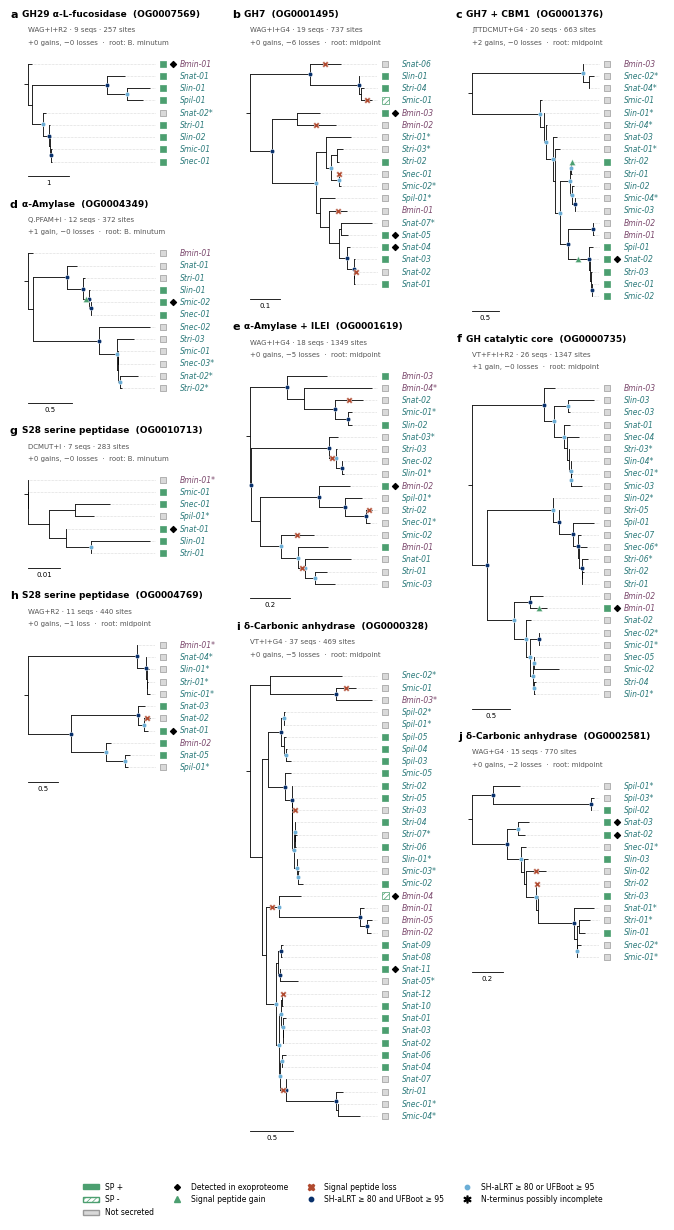

Saved /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/FigS_secretion_evolution_supp.{pdf,svg,png}


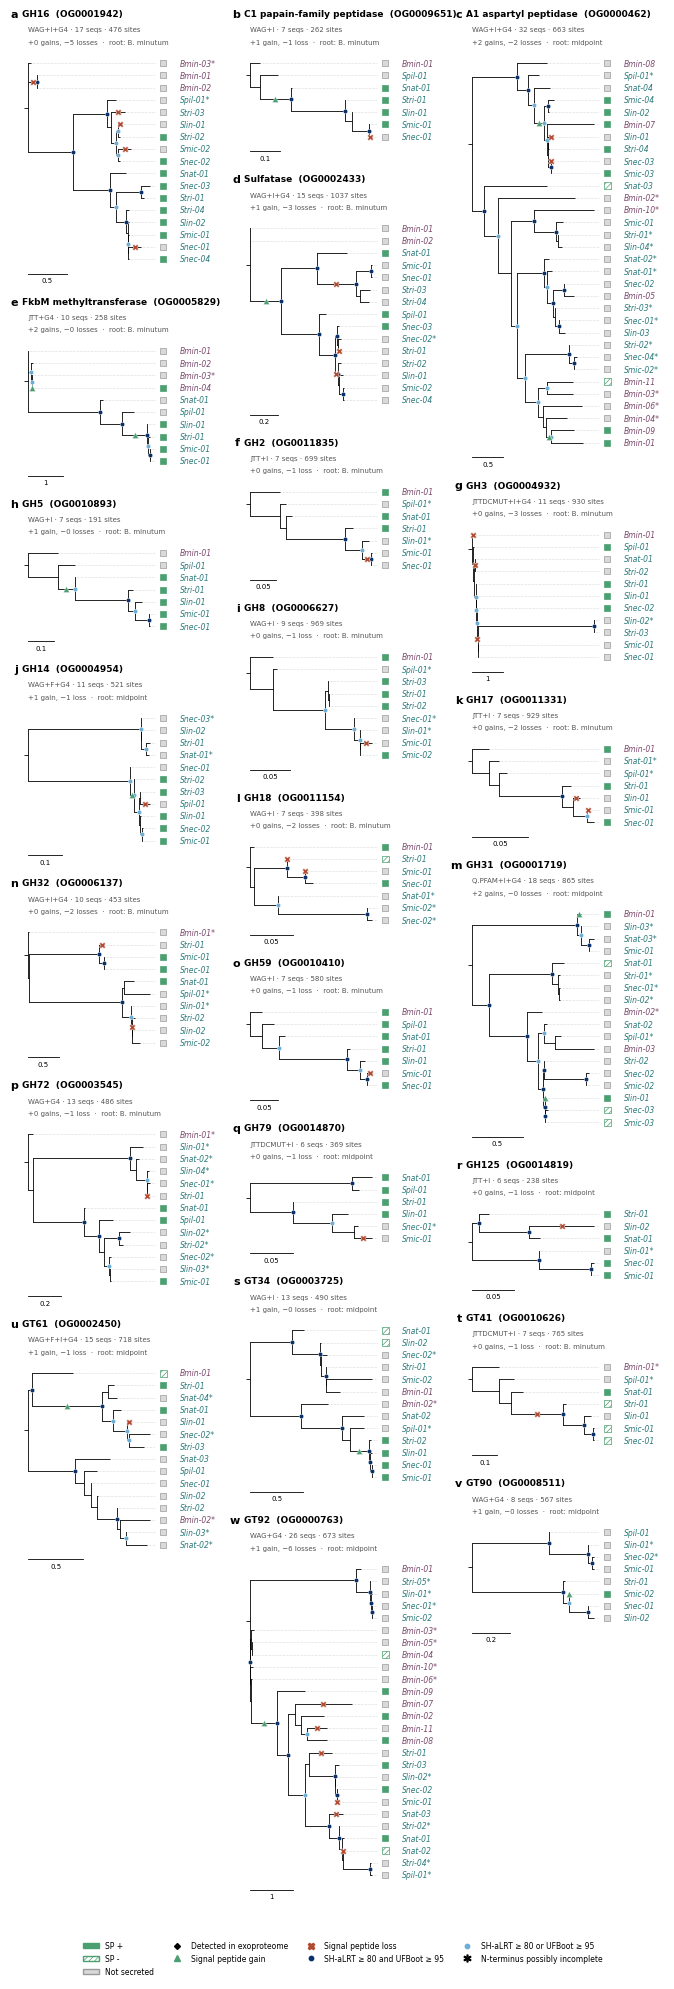

In [12]:
# ===================== Cell 5 — figures: phylograms with branch lengths, fixed-size symbols =====================
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.transforms import offset_copy

plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': FONT, 'font.size': 6, 'pdf.fonttype': 42,
                     'svg.fonttype': 'none', 'hatch.linewidth': 0.5})

# ---- display options ----
# Node support (IQ-TREE: SH-aLRT and UFBoot), colour-coded by the standard joint thresholds
ALRT_MIN, UFB_MIN = 80, 95
SUPPORT_CLASSES = [   # (label, colour) — strongest first
    (f'SH-aLRT ≥ {ALRT_MIN} and UFBoot ≥ {UFB_MIN}', '#08306B'),
    (f'SH-aLRT ≥ {ALRT_MIN} or UFBoot ≥ {UFB_MIN}',  '#6BAED6'),
]
ROW_H               = 0.125   # inches per tip row (identical in every panel) - more = airier
NCOL                = 3       # panels are packed into this many columns (shortest column first)
SYM = dict(tip=24, node=10, gain=20, loss=20, det=9)   # marker areas in pt^2, identical everywhere
TIP_GAP_PT, DET_GAP_PT, LAB_GAP_PT = 6, 13, 18        # symbol/label offsets right of the tip column (points)

def phylogram_layout(tree):
    y = {id(t): i for i, t in enumerate(tree.get_terminals())}
    x = {id(tree.root): 0.0}
    for c in tree.find_clades(order='preorder'):
        for ch in c.clades:
            x[id(ch)] = x[id(c)] + (ch.branch_length or 0.0)
    for c in tree.find_clades(order='postorder'):
        if not c.is_terminal():
            y[id(c)] = (y[id(c.clades[0])] + y[id(c.clades[-1])]) / 2
    return x, y, max(x.values())

def nice_scale(H):
    target = H * 0.2
    for v in (0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1, 2, 5):
        if v >= target:
            return v
    return 10

def draw_phylogram(ax, tree, x, y, H, lw=0.6):
    stub = 0.03 * H
    ax.plot([-stub, 0], [y[id(tree.root)]] * 2, color='black', lw=lw, solid_capstyle='butt')
    for c in tree.find_clades(order='preorder'):
        if c.is_terminal():
            continue
        ys = [y[id(ch)] for ch in c.clades]
        ax.plot([x[id(c)]] * 2, [min(ys), max(ys)], color='black', lw=lw)
        for ch in c.clades:
            ax.plot([x[id(c)], x[id(ch)]], [y[id(ch)]] * 2, color='black', lw=lw, solid_capstyle='butt')

def support_class(sup):
    """0 = strong (both thresholds), 1 = moderate (one), None = weak or no value."""
    if not sup:
        return None
    alrt, ufb = sup
    ok = [v >= t for v, t in ((alrt, ALRT_MIN), (ufb, UFB_MIN)) if v is not None]
    if ok and all(ok) and len(ok) == 2:
        return 0
    return 1 if any(ok) else None

def scale_bar(ax, H, ybar):
    L = nice_scale(H)
    ax.plot([0, L], [ybar, ybar], color='black', lw=0.6)
    ax.text(L / 2, ybar + 0.3, f'{L:g}', ha='center', va='top', fontsize=5)

def draw_gene_tree(ax, og, n_rows):
    tree, rooting = GENE_TREES[og]
    _, S, ev = PLOT_RECON[og]
    g = tips[tips.orthogroup == og].set_index('tip')
    x, y, H = phylogram_layout(tree)
    XT = H * 1.04                                   # aligned tip column
    draw_phylogram(ax, tree, x, y, H)
    fig = ax.figure
    off = lambda pts: offset_copy(ax.transData, fig=fig, x=pts, units='points')

    # node support (re-attached by bipartition, so it is correct after re-rooting), colour-coded
    sup_map, all_names, ref = SUPPORT[og]
    for c in tree.get_nonterminals():
        if c is tree.root:
            continue
        k = support_class(sup_map.get(split_key([t.name for t in c.get_terminals()], all_names, ref)))
        if k is not None:
            ax.scatter(x[id(c)], y[id(c)], s=SYM['node'], color=SUPPORT_CLASSES[k][1],
                       edgecolor='white', linewidths=0.3, zorder=4)
    parent = {id(ch): c for c in tree.find_clades() for ch in c.clades}
    for node, kind in ev:
        xm = (x[id(parent[id(node)])] + x[id(node)]) / 2
        if kind == 'gain':
            ax.scatter(xm, y[id(node)], s=SYM['gain'], marker='^', color=GAIN_COLOR,
                       edgecolor='white', linewidths=0.3, zorder=5)
        else:
            ax.scatter(xm, y[id(node)], s=SYM['loss'], marker='X', color=LOSS_COLOR,
                       edgecolor='white', linewidths=0.3, zorder=5)

    # tips: dotted guide to aligned column, then status square, detection, label
    for t in tree.get_terminals():
        st, strain, detd = g.loc[t.name, 'status'], g.loc[t.name, 'strain'], g.loc[t.name, 'detected']
        yy = y[id(t)]
        ax.plot([x[id(t)], XT], [yy, yy], ls=(0, (1, 1.5)), lw=0.4, color='#BBBBBB', zorder=1)
        kw = dict(s=SYM['tip'], marker='s', linewidths=0.5, zorder=3, clip_on=False,
                  transform=off(TIP_GAP_PT))
        if st == 'SP+':
            ax.scatter(XT, yy, facecolor=SECRETED_COLOR, edgecolor=SECRETED_COLOR, **kw)
        elif st == 'SP-':
            ax.scatter(XT, yy, facecolor='white', edgecolor=SECRETED_COLOR, hatch='//////', **kw)
        else:
            ax.scatter(XT, yy, facecolor=NONSEC_COLOR, edgecolor='#9A9A9A', **kw)
        if detd:
            ax.scatter(XT, yy, s=SYM['det'], marker='D', color='black', zorder=3, clip_on=False,
                       transform=off(DET_GAP_PT))
        flag = '*' if f'{t.name}|{og}' in globals().get('FLAGGED', set()) else ''
        ax.text(XT, yy, t.name.replace('_', '-') + flag, transform=off(LAB_GAP_PT), va='center', ha='left',
                style='italic', color=CLADE_COLOR[STRAIN_CLADE[strain]], fontsize=5.5, clip_on=False)

    gains, losses = count_events(ev)
    ax.set_title(f'{SELECTED[og][0]}  ({og})', loc='left', fontsize=6.5, fontweight='bold', pad=2)
    st_ = TREE_STATS.get(og, {})
    stats = f"{st_.get('model', '?')} · {len(g)} seqs · {st_.get('n_sites', '?')} sites" if st_ else ''
    ax.text(0, -2.5, stats, fontsize=5, color='#555555', va='bottom')
    ax.text(0, -1.5, f'+{gains} gain{"s" * (gains != 1)}, −{losses} loss{"es" * (losses != 1)}'
                     f'  ·  root: {rooting}', fontsize=5, color='#555555', va='bottom')
    scale_bar(ax, H, len(g) + 0.2)
    ax.set_xlim(-0.05 * H, XT / 0.66)               # right 34% of each panel kept for symbols/labels
    ax.set_ylim(n_rows + 2.9, -3.6)                 # tip spacing set by ROW_H; room below for scale bar
    ax.axis('off')

def legend_handles():
    return [Patch(facecolor=SECRETED_COLOR, edgecolor=SECRETED_COLOR, label='SP +'),
            Patch(facecolor='white', edgecolor=SECRETED_COLOR, hatch='//////', label='SP -'),
            Patch(facecolor=NONSEC_COLOR, edgecolor='#9A9A9A', label='Not secreted'),
            Line2D([], [], marker='D', ls='', ms=np.sqrt(SYM['det']), color='black', label='Detected in exoproteome'),
            Line2D([], [], marker='^', ls='', ms=np.sqrt(SYM['gain']), color=GAIN_COLOR, label='Signal peptide gain'),
            Line2D([], [], marker='X', ls='', ms=np.sqrt(SYM['loss']), color=LOSS_COLOR, label='Signal peptide loss'),
            *[Line2D([], [], marker='o', ls='', ms=np.sqrt(SYM['node']), color=col, label=lab)
              for lab, col in SUPPORT_CLASSES],
            Line2D([], [], ls='', marker='$*$', ms=5, color='black', label='N-terminus possibly incomplete')]

def panel_figure(ogs, stem, ncol=NCOL):
    """Masonry layout: each panel goes to the currently shortest column, so a large tree
    (e.g. 37 tips) does not force empty space next to small ones. Panel letters follow
    the order of `ogs`; tip spacing (ROW_H) is identical in every panel."""
    size = {og: len(tips[tips.orthogroup == og]) + 6.5 for og in ogs}   # extra rows: title, subtitle, scale bar, gap
    cols, col_h = [[] for _ in range(ncol)], [0] * ncol
    for og in ogs:
        k = col_h.index(min(col_h))
        cols[k].append(og); col_h[k] += size[og]
    H_rows = max(col_h)
    fig = plt.figure(figsize=(170 / 25.4, H_rows * ROW_H + 0.6))
    outer = gridspec.GridSpec(1, ncol, wspace=0.12, left=0.02, right=0.98, top=0.98,
                              bottom=0.6 / (H_rows * ROW_H + 0.6))
    letter = {og: chr(97 + i) for i, og in enumerate(ogs)}
    for k, col in enumerate(cols):
        if not col:
            continue
        heights = [size[og] for og in col] + [H_rows - col_h[k] + 1e-6]   # filler keeps rows aligned
        inner = gridspec.GridSpecFromSubplotSpec(len(heights), 1, subplot_spec=outer[0, k],
                                                 height_ratios=heights, hspace=0.0)
        for i, og in enumerate(col):
            ax = fig.add_subplot(inner[i, 0])
            draw_gene_tree(ax, og, size[og] - 6.5)
            ax.text(-0.02, 1.0, letter[og], transform=ax.transAxes,
                    fontsize=8, fontweight='bold', va='bottom', ha='right')
    fig.legend(handles=legend_handles(), loc='lower center', ncol=4, frameon=False, fontsize=5.5,
               bbox_to_anchor=(0.5, 0.0))
    save_fig(fig, stem)          # writes .pdf, .svg (editable text) and .png (600 dpi)
    plt.show()

panel_figure([og for og, v in SELECTED.items() if v[2]], 'Fig_secretion_evolution_main')
panel_figure([og for og, v in SELECTED.items() if not v[2]], 'FigS_secretion_evolution_supp')

In [13]:
# Near-zero branches: which tips, which species, and are the sequences identical in the trimmed alignment?
from Bio import SeqIO
ZERO = 1e-4
rows_z = []
for og in SELECTED:
    tree, _ = GENE_TREES[og]
    g = tips[tips.orthogroup == og].set_index('tip')
    trim_path = f'{TREE_DIR}/{og}.trim.fa' if os.path.exists(f'{TREE_DIR}/{og}.trim.fa') else f'{TREE_DIR}/{og}.aln.fa'
    aln = {r.id: str(r.seq) for r in SeqIO.parse(trim_path, 'fasta')}
    parent = {id(ch): c for c in tree.find_clades() for ch in c.clades}
    for c in tree.find_clades():
        if c is tree.root or (c.branch_length or 0) >= ZERO:
            continue
        sib = [k for k in parent[id(c)].clades if k is not c]
        names = [t.name for t in c.get_terminals()]
        sib_names = [t.name for s_ in sib for t in s_.get_terminals()]
        same = (len(names) == 1 and len(sib_names) == 1 and names[0] in aln and sib_names[0] in aln
                and aln[names[0]] == aln[sib_names[0]])
        rows_z.append(dict(orthogroup=og, node=','.join(names), sister=','.join(sib_names)[:60],
                           species=','.join(sorted({g.loc[n, 'strain'] for n in names})),
                           branch_length=c.branch_length, identical_to_sister=same))
zero_tab = pd.DataFrame(rows_z)
print(zero_tab.to_string(index=False) if len(zero_tab) else 'No near-zero branches')
print('\nPer OG:', zero_tab.groupby('orthogroup').size().to_dict() if len(zero_tab) else {})

orthogroup                                                                                                                                            node                                                       sister                            species  branch_length  identical_to_sister
 OG0001495                                                                                                                                         Slin_01                                              Stri_04,Smic_01                               Slin   2.291400e-06                False
 OG0001495                                                                                                                                         Snec_01                                                      Smic_02                               Snec   2.349400e-06                False
 OG0001495                                                                                                                                 

# Cell 6 - Single-copy OGs on the species tree

Single-copy secretome-associated OGs: 103 | mixed: 102
Root branch lengths: {'Bmin': 0.241571, 'Symbiodinium stem': 0.241571}
character                                     SP+          SP+ or SP-         
model                                       Fitch Weighted      Fitch Weighted
category                                                                      
Ancestral, losses only                          6       31          9       38
Ancestral, retained in all                      1        1          1        1
Multiple independent gains                     13        4         15        5
Multiple independent gains (ambiguous root)    15        1         20        4
No SP+ member                                  14       14          0        0
Single gain                                    41       33         43       34
Single gain (ambiguous root)                    9        8          6        9
Single gain, then losses                        3        7          6        7
Singl

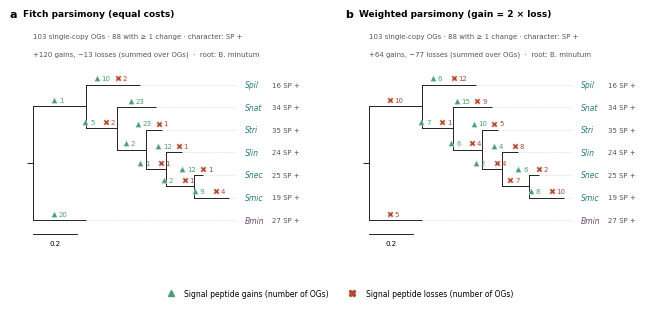

In [ ]:
# ===================== Cell 6 — single-copy OGs on the species tree (same display as Cell 5) =====================
# Needs Cell 5 in this session (drawing helpers, symbol sizes, colours).
from Bio import Phylo
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.transforms import offset_copy
assert 'draw_phylogram' in globals(), 'Run Cell 5 first in this session (it defines the drawing helpers).'

s1 = read_table(TABLE_S1)
SCOL = {s: status_col(s1, s) for s in STRAINS}
st_cols = list(SCOL.values())
single = s1[(s1.N_strains_present == 7) & (s1.N_proteins == 7)
            & s1[st_cols].apply(lambda r: all(';' not in str(v) for v in r), axis=1)].copy()
print('Single-copy secretome-associated OGs:', len(single),
      '| mixed:', (single.Membership == 'Mixed').sum())

sp_tree = Phylo.read(SPECIES_TREE, 'newick')
leaf_strain = {t.name: strain_from_label(t.name) for t in sp_tree.get_terminals()}
bmin_leaf = [t for t in sp_tree.get_terminals() if leaf_strain[t.name] == 'Bmin'][0]
if bmin_leaf not in sp_tree.root.clades:          # file is already Bmin-rooted; root only if not
    sp_tree.root_with_outgroup(bmin_leaf)
SPLIT_SPECIES_ROOT = False   # True: split the root edge evenly; False: keep lengths exactly as in Panel C
if SPLIT_SPECIES_ROOT:
    split_root_branch(sp_tree)
print('Root branch lengths:', {leaf_strain.get(c.name, 'Symbiodinium stem'): c.branch_length
                               for c in sp_tree.root.clades})
for c in sp_tree.get_nonterminals():               # drop species-tree support labels (not shown)
    c.name, c.confidence = None, None
ORDER = {s: i for i, s in enumerate(STRAINS)}      # fixed display order: Spil ... Smic, Bmin last
for c in sp_tree.get_nonterminals(order='postorder'):
    c.clades.sort(key=lambda k: min(ORDER[leaf_strain[t.name]] for t in k.get_terminals()))

def classify(root, gains, losses):
    if root == 1:
        return 'Ancestral, losses only' if losses else 'Ancestral, retained in all'
    if gains == 0:
        return 'No SP+ member'
    if gains == 1:
        return 'Single gain' if losses == 0 else 'Single gain, then losses'
    return 'Multiple independent gains'

rows, branch = [], {(m, id(c)): [0, 0] for m in MODELS for c in sp_tree.find_clades()}
for _, r in single.iterrows():
    for cname, fn in CHARACTERS.items():
        state = {leaf: fn(r[SCOL[leaf_strain[leaf]]]) for leaf in leaf_strain}
        for mname, gc in MODELS.items():
            best, recs = sankoff(sp_tree, state, gc)
            counts = [count_events(ev) for _, _, ev in recs]
            root, _, ev = recs[0]
            gains, losses = counts[0]
            rows.append(dict(orthogroup=r.orthogroup, character=cname, model=mname,
                             pattern=''.join(str(state[l.name]) for l in sp_tree.get_terminals()),
                             root_state='/'.join(str(x) for x, _, _ in recs),
                             gains=gains, losses=losses, ambiguous=len(set(counts)) > 1,
                             category=classify(root, gains, losses) + (' (ambiguous root)' if len(set(counts)) > 1 else '')))
            if cname == 'SP+':
                for node, kind in ev:
                    branch[(mname, id(node))][0 if kind == 'gain' else 1] += 1
sc = pd.DataFrame(rows)
sc.to_csv(f'{DATA_DIR}/single_copy_secretion_parsimony.tsv', sep='\t', index=False)
tab = sc.groupby(['character', 'model', 'category']).size().unstack(['character', 'model']).fillna(0).astype(int)
tab.to_csv(f'{DATA_DIR}/single_copy_secretion_categories.tsv', sep='\t')
print(tab.to_string())

# ---- figure: same visual language as Cell 5 ----
plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': FONT, 'font.size': 6, 'pdf.fonttype': 42,
                     'svg.fonttype': 'none', 'hatch.linewidth': 0.5})
SP_ROW_H = 0.22                                   # inches per species row (7 tips, so a little airier than Cell 5)
EV_STEP_PT = 15                                   # horizontal spacing of the gain / loss symbols on a branch
n_single = len(single)
fsp = sc[(sc.character == 'SP+') & (sc.model == 'Fitch')]
n_changed = int(((fsp.gains + fsp.losses) > 0).sum())
sp_plus = {s: int((single[SCOL[s]] == 'SP+').sum()) for s in STRAINS}
MODEL_TITLE = {'Fitch': 'Fitch parsimony (equal costs)',
               'Weighted': f'Weighted parsimony (gain = {GAIN_COST_WEIGHTED} × loss)'}

def draw_species_panel(ax, mname):
    tree = sp_tree
    x, y, H = phylogram_layout(tree)
    XT = H * 1.04
    draw_phylogram(ax, tree, x, y, H)
    fig = ax.figure
    off = lambda dx, dy=0: offset_copy(ax.transData, fig=fig, x=dx, y=dy, units='points')
    parent = {id(ch): c for c in tree.find_clades() for ch in c.clades}
    tot_g = tot_l = 0
    for c in tree.find_clades():
        if c is tree.root:
            continue
        gn, ls = branch[(mname, id(c))]
        tot_g, tot_l = tot_g + gn, tot_l + ls
        items = [(n, k, m, col) for n, k, m, col in ((gn, 'gain', '^', GAIN_COLOR), (ls, 'loss', 'X', LOSS_COLOR)) if n]
        if not items:
            continue
        xm, yy = (x[id(parent[id(c)])] + x[id(c)]) / 2, y[id(c)]
        x0 = -EV_STEP_PT * (len(items) - 1) / 2 - 4          # centre the symbol + count pairs on the branch
        for i, (n, k, m, col) in enumerate(items):
            dx = x0 + i * EV_STEP_PT
            ax.scatter(xm, yy, s=SYM[k], marker=m, color=col, edgecolor='white', linewidths=0.3,
                       zorder=5, clip_on=False, transform=off(dx, 4.5))
            ax.text(xm, yy, str(n), transform=off(dx + 3.5, 4.5), va='center', ha='left',
                    fontsize=5, color=col, clip_on=False)
    for t in tree.get_terminals():
        s, yy = leaf_strain[t.name], y[id(t)]
        ax.plot([x[id(t)], XT], [yy, yy], ls=(0, (1, 1.5)), lw=0.4, color='#BBBBBB', zorder=1)
        ax.text(XT, yy, s, transform=off(6), va='center', ha='left', style='italic',
                color=CLADE_COLOR[STRAIN_CLADE[s]], fontsize=5.5, clip_on=False)
        ax.text(XT, yy, f'{sp_plus[s]} SP +', transform=off(26), va='center', ha='left',
                fontsize=5, color='#555555', clip_on=False)
    n = len(tree.get_terminals())
    ax.set_title(MODEL_TITLE[mname], loc='left', fontsize=6.5, fontweight='bold', pad=2)
    ax.text(0, -2.0, f'{n_single} single-copy OGs · {n_changed} with ≥ 1 change · character: SP +',
            fontsize=5, color='#555555', va='bottom')
    ax.text(0, -1.2, f'+{tot_g} gains, −{tot_l} losses (summed over OGs)  ·  root: B. minutum',
            fontsize=5, color='#555555', va='bottom')
    scale_bar(ax, H, n - 1 + 0.6)
    ax.set_xlim(-0.05 * H, XT / 0.70)
    ax.set_ylim(n + 1.2, -2.9)
    ax.axis('off')

n_rows = len(sp_tree.get_terminals()) + 4.8
fig_h = n_rows * SP_ROW_H + 0.35
fig, axes = plt.subplots(1, 2, figsize=(170 / 25.4, fig_h))
fig.subplots_adjust(left=0.03, right=0.98, top=0.97, bottom=0.35 / fig_h, wspace=0.12)
for i, (ax, mname) in enumerate(zip(axes, MODELS)):
    draw_species_panel(ax, mname)
    ax.text(-0.02, 1.0, chr(97 + i), transform=ax.transAxes, fontsize=8, fontweight='bold', va='bottom', ha='right')
fig.legend(handles=[Line2D([], [], marker='^', ls='', ms=np.sqrt(SYM['gain']), color=GAIN_COLOR,
                           label='Signal peptide gains (number of OGs)'),
                    Line2D([], [], marker='X', ls='', ms=np.sqrt(SYM['loss']), color=LOSS_COLOR,
                           label='Signal peptide losses (number of OGs)')],
           loc='lower center', ncol=2, frameon=False, fontsize=5.5, bbox_to_anchor=(0.5, 0.0))
save_fig(fig, 'FigS_single_copy_gain_loss_species_tree')
plt.show()

# Appendix

## Appendix: *P. glacialis* outgroup

1. Put the *P. glacialis* proteome at OUTGROUP_FAA (Cell 0). Run Cells 0 → 1 → 2 → 3, then B1 (and B2).

2. Classify *P. glacialis* with the secretome pipeline on the HPC (whole proteome or outgroup_hits.faa) and copy Pgla_SP_pos/SP_neg_secretome_final.faa to OUTGROUP_PIPE_DIR.

3. Run B3 (trees with outgroup go to secretion_evolution/with_outgroup/).

4. Set USE_OUTGROUP = True in Cell 0, re-run Cell 0, then Cells 4 → 4b → 4c → 4d → 5.

Known result (Oct 2026): 8 of 10 OGs have a *P. glacialis* homologue; the two δ-CA OGs have none (PF10563 absent from the P. glacialis predicted proteome; detected in 37/52 δ-CA members).

### Cell B1

In [ ]:
# ===================== Cell B1 — outgroup search (DIAMOND, reciprocal best hits) =====================
# Forward: OG members -> P. glacialis proteome. Reverse: candidates -> the seven proteomes
# (OrthoFinder WorkingDirectory copies from Cell 2). Writes outgroup_hits.faa/.tsv to Drive.
import shutil
if not os.path.exists('/content/bin/diamond'):
    os.makedirs('/content/bin', exist_ok=True)
    url = github_asset('bbuchfink/diamond', r'diamond-linux64\.tar\.gz$')
    sh(f'wget -q {url} -O /content/diamond.tgz && tar -xzf /content/diamond.tgz -C /content/bin')
DIAMOND = '/content/bin/diamond'
assert 'mem' in globals() and 'tip' in mem.columns, 'Run Cell 2 first in this session.'
OUT_RUN = '/content/outgroup_run'; os.makedirs(OUT_RUN, exist_ok=True)
FMT = 'qseqid sseqid pident length evalue bitscore qlen slen qstart qend sstart send'.split()
first = lambda x: str(x).split()[0]

def diamond_blastp(query, db, out, max_targets):
    sh(f'{DIAMOND} blastp -q {query} -d {db} -o {out} --outfmt 6 {" ".join(FMT)} '
       f'--more-sensitive -e {OUTGROUP_EVALUE} --max-target-seqs {max_targets} --threads 2 --quiet')
    return pd.read_csv(out, sep='\t', names=FMT, dtype={'qseqid': str, 'sseqid': str}) \
        if os.path.getsize(out) else pd.DataFrame(columns=FMT)

# 1) forward search
with open(f'{OUT_RUN}/query.faa', 'w') as fh:
    for og, t, q in mem[['orthogroup', 'tip', 'sequence']].itertuples(index=False):
        fh.write(f'>{og}|{t}\n{q.replace("*", "")}\n')
shutil.copy(OUTGROUP_FAA, f'{OUT_RUN}/outgroup.faa')
out_seqs = {first(r.id): str(r.seq).replace('*', '') for r in SeqIO.parse(f'{OUT_RUN}/outgroup.faa', 'fasta')}
sh(f'{DIAMOND} makedb --in {OUT_RUN}/outgroup.faa -d {OUT_RUN}/outgroup --quiet')
fwd = diamond_blastp(f'{OUT_RUN}/query.faa', f'{OUT_RUN}/outgroup', f'{OUT_RUN}/fwd.tsv', 25)
fwd['og'] = fwd.qseqid.str.split('|').str[0]
fwd['scov'] = (fwd.send - fwd.sstart).abs().add(1) / fwd.slen
fwd = fwd[fwd.scov >= OUTGROUP_MIN_SCOV]
cand = (fwd.groupby(['og', 'sseqid'], as_index=False)
           .agg(bitscore=('bitscore', 'max'), scov=('scov', 'max'), pident=('pident', 'max'))
           .sort_values(['og', 'bitscore'], ascending=[True, False]).groupby('og').head(5))

# 2) reverse search against all seven proteomes (OrthoFinder IDs, e.g. '3_1234')
for k in species_files:
    local_copy(f'Species{k}.fa')
with open(f'{OUT_RUN}/ingroup_all.faa', 'w') as fh:
    for k in species_files:
        for r in SeqIO.parse(f'{LOCAL_OF}/Species{k}.fa', 'fasta'):
            fh.write(f'>{r.id}\n{r.seq}\n')
with open(f'{OUT_RUN}/candidates.faa', 'w') as fh:
    for i in sorted(set(cand.sseqid)):
        fh.write(f'>{i}\n{out_seqs[first(i)]}\n')
sh(f'{DIAMOND} makedb --in {OUT_RUN}/ingroup_all.faa -d {OUT_RUN}/ingroup --quiet')
rev = diamond_blastp(f'{OUT_RUN}/candidates.faa', f'{OUT_RUN}/ingroup', f'{OUT_RUN}/rev.tsv', 1)
rbh_target = dict(rev.sort_values('bitscore', ascending=False).drop_duplicates('qseqid')[['qseqid', 'sseqid']].values)
members = mem.groupby('orthogroup').of_id.apply(set).to_dict()
cand['rbh'] = [rbh_target.get(sid) in members.get(og, set()) for og, sid in zip(cand.og, cand.sseqid)]

# 3) one outgroup sequence per OG: reciprocal best hit, else best-scoring hit
keep, seen = [], set()
for og in SELECTED:
    g = cand[cand.og == og]
    pool = g[g.rbh].assign(selection='RBH')
    if pool.empty and OUTGROUP_FALLBACK_BEST_HIT:
        pool = g.assign(selection='best_hit')
    for _, r in pool.iterrows():
        if out_seqs[first(r.sseqid)] in seen:
            continue
        keep.append(dict(orthogroup=og, outgroup_id=r.sseqid, selection=r.selection,
                         bitscore=r.bitscore, pident=r.pident, scov=round(r.scov, 3)))
        seen.add(out_seqs[first(r.sseqid)]); break
hits = pd.DataFrame(keep, columns=['orthogroup', 'outgroup_id', 'selection', 'bitscore', 'pident', 'scov'])
hits.to_csv(OUTGROUP_HITS_TSV, sep='\t', index=False)
with open(OUTGROUP_HITS_FAA, 'w') as fh:
    for i in hits.outgroup_id.unique():
        fh.write(f'>{i}\n{out_seqs[first(i)]}\n')
print(hits.to_string(index=False))
print('\nOGs without an outgroup:', [og for og in SELECTED if og not in set(hits.orthogroup)] or 'none')
print(f'\nNEXT: run {os.path.basename(OUTGROUP_HITS_FAA)} through the secretome pipeline on the HPC and copy the '
      f'SP+/SP- outputs to {OUTGROUP_PIPE_DIR}/')

### Cell B2

In [ ]:
# ===================== Cell B2 — rescue search for OGs without an outgroup; best_hit check =====================
# Relaxed DIAMOND (E<=1e-5, no coverage filter) + Pfam domain search (hmmsearch) in P. glacialis.
# A rescued outgroup must carry the OG's Pfam domain, be a reciprocal best hit, and cover >=30% of query or subject.
import gzip
assert 'hits' in globals() and 'rbh_target' in globals(), 'Run Cell B1 first in this session.'
RESCUE_EVALUE, RESCUE_MIN_COV = 1e-5, 0.3
of2og = dict(zip(mem.of_id, mem.orthogroup))

print('best_hit outgroups - OG of their reverse best hit:')
for og, oid in hits[hits.selection == 'best_hit'][['orthogroup', 'outgroup_id']].itertuples(index=False):
    print(f'  {og}: {oid} -> {of2og.get(rbh_target.get(oid), "outside the selected OGs")}')

MISSING = [og for og in SELECTED if og not in set(hits.orthogroup)]
print('\nRescue search for:', MISSING)
if MISSING:
    sh('apt-get -qq install -y hmmer > /dev/null')
    pf_hits = {}
    for pf in sorted({SELECTED[og][1] for og in MISSING}):
        hmm = f'{OUT_RUN}/{pf}.hmm'
        if not os.path.exists(hmm):
            raw = urllib.request.urlopen(f'https://www.ebi.ac.uk/interpro/wwwapi//entry/pfam/{pf}?annotation=hmm').read()
            open(hmm, 'wb').write(gzip.decompress(raw) if raw[:2] == b'\x1f\x8b' else raw)
        sh(f'hmmsearch --cpu 2 -E {RESCUE_EVALUE} --domtblout {OUT_RUN}/{pf}.domtbl {hmm} {OUT_RUN}/outgroup.faa > /dev/null')
        pf_hits[pf] = {l.split()[0] for l in open(f'{OUT_RUN}/{pf}.domtbl') if not l.startswith('#')}
        # positive control: the same profile on the ingroup members of these OGs
        with open(f'{OUT_RUN}/{pf}_members.faa', 'w') as fh:
            for t, q in mem[mem.orthogroup.isin([o for o in MISSING if SELECTED[o][1] == pf])][['tip', 'sequence']].itertuples(index=False):
                fh.write(f'>{t}\n{q.replace("*", "")}\n')
        sh(f'hmmsearch --cpu 2 -E {RESCUE_EVALUE} --domtblout {OUT_RUN}/{pf}_members.domtbl {hmm} {OUT_RUN}/{pf}_members.faa > /dev/null')
        n_in = len({l.split()[0] for l in open(f'{OUT_RUN}/{pf}_members.domtbl') if not l.startswith('#')})
        n_all = mem.orthogroup.isin([o for o in MISSING if SELECTED[o][1] == pf]).sum()
        print(f'  {pf}: {len(pf_hits[pf])} P. glacialis proteins; {n_in} of {n_all} ingroup members (positive control)')

    with open(f'{OUT_RUN}/q_missing.faa', 'w') as fh:
        for og, t, q in mem[mem.orthogroup.isin(MISSING)][['orthogroup', 'tip', 'sequence']].itertuples(index=False):
            fh.write(f'>{og}|{t}\n{q.replace("*", "")}\n')
    sh(f'{DIAMOND} blastp -q {OUT_RUN}/q_missing.faa -d {OUT_RUN}/outgroup -o {OUT_RUN}/fwd_relaxed.tsv '
       f'--outfmt 6 {" ".join(FMT)} --ultra-sensitive -e {RESCUE_EVALUE} --max-target-seqs 25 --threads 2 --quiet')
    rel = pd.read_csv(f'{OUT_RUN}/fwd_relaxed.tsv', sep='\t', names=FMT, dtype={'qseqid': str, 'sseqid': str}) \
        if os.path.getsize(f'{OUT_RUN}/fwd_relaxed.tsv') else pd.DataFrame(columns=FMT)
    if rel.empty:
        print('\nNo relaxed DIAMOND hits.')
    else:
        rel['og'] = rel.qseqid.str.split('|').str[0]
        rel['qcov'] = (rel.qend - rel.qstart).abs().add(1) / rel.qlen
        rel['scov'] = (rel.send - rel.sstart).abs().add(1) / rel.slen
        rc = (rel.groupby(['og', 'sseqid'], as_index=False)
                 .agg(bitscore=('bitscore', 'max'), evalue=('evalue', 'min'), pident=('pident', 'max'),
                      qcov=('qcov', 'max'), scov=('scov', 'max'), slen=('slen', 'first'))
                 .sort_values(['og', 'bitscore'], ascending=[True, False]).groupby('og').head(5))
        rc['pfam'] = [sid in pf_hits[SELECTED[og][1]] for og, sid in zip(rc.og, rc.sseqid)]
        with open(f'{OUT_RUN}/cand_relaxed.faa', 'w') as fh:
            for i in rc.sseqid.unique():
                fh.write(f'>{i}\n{out_seqs[first(i)]}\n')
        rv = diamond_blastp(f'{OUT_RUN}/cand_relaxed.faa', f'{OUT_RUN}/ingroup', f'{OUT_RUN}/rev_relaxed.tsv', 1)
        rv_t = dict(rv.sort_values('bitscore', ascending=False).drop_duplicates('qseqid')[['qseqid', 'sseqid']].values)
        rc['rev_hit_OG'] = [of2og.get(rv_t.get(sid), '-') for sid in rc.sseqid]
        rc['rbh'] = rc.rev_hit_OG == rc.og
        print('\nRelaxed candidates (top 5 per OG):')
        print(rc.round(3).to_string(index=False))
        used = set(hits.outgroup_id)
        ok = rc[rc.pfam & rc.rbh & ((rc.qcov >= RESCUE_MIN_COV) | (rc.scov >= RESCUE_MIN_COV))]
        new = []
        for og in MISSING:
            for _, r in ok[(ok.og == og) & ~ok.sseqid.isin(used)].head(1).iterrows():
                new.append(dict(orthogroup=og, outgroup_id=r.sseqid, selection='RBH_relaxed',
                                bitscore=r.bitscore, pident=r.pident, scov=round(r.scov, 3)))
                used.add(r.sseqid)
        if new:
            hits = pd.concat([hits, pd.DataFrame(new)], ignore_index=True)
            hits.to_csv(OUTGROUP_HITS_TSV, sep='\t', index=False)
            with open(OUTGROUP_HITS_FAA, 'w') as fh:
                for i in hits.outgroup_id.unique():
                    fh.write(f'>{i}\n{out_seqs[first(i)]}\n')
            print('\nRescued and written to outgroup_hits.faa/.tsv:')
            print(pd.DataFrame(new).to_string(index=False))
print('\nOGs without outgroup (B. minutum / midpoint root):',
      [og for og in SELECTED if og not in set(hits.orthogroup)] or 'none')
print('outgroup_hits.faa has', hits.outgroup_id.nunique(), 'sequences')

### Cell B3

In [ ]:
# ===================== Cell B3 — trees with the P. glacialis outgroup (written to OG_DIR) =====================
# Needs Cells 0-3 and B1 in this session, plus the P. glacialis secretome-pipeline output in OUTGROUP_PIPE_DIR
# (whole-proteome output works: sequences are matched by MD5).
assert 'build_trees' in globals(), 'Run Cell 3 first in this session (it defines build_trees).'
for p_ in (OUTGROUP_HITS_TSV, OUTGROUP_HITS_FAA, OUTGROUP_SP_POS, OUTGROUP_SP_NEG):
    if not os.path.exists(p_):
        raise FileNotFoundError(f'{p_} not found (Cell B1 / HPC secretome pipeline).')
og_status = {}
for path, cls in ((OUTGROUP_SP_POS, 'SP+'), (OUTGROUP_SP_NEG, 'SP-')):
    for r in SeqIO.parse(path, 'fasta'):
        og_status[seq_md5(r.seq)] = cls
out_hit_seqs = {str(r.id).split()[0]: str(r.seq).replace('*', '') for r in SeqIO.parse(OUTGROUP_HITS_FAA, 'fasta')}
hits = pd.read_csv(OUTGROUP_HITS_TSV, sep='\t', dtype=str)
out_rows = []
for og, oid in hits[['orthogroup', 'outgroup_id']].itertuples(index=False):
    s_ = out_hit_seqs[oid.split()[0]]
    out_rows.append(dict(orthogroup=og, protein_id=oid, strain=OUTGROUP_NAME, tip=f'{OUTGROUP_NAME}_01',
                         sequence=s_, status=og_status.get(seq_md5(s_), 'not_secreted'),
                         detected=False, outgroup=True))
ext = pd.concat([mem.assign(outgroup=False), pd.DataFrame(out_rows)], ignore_index=True)
ext.drop(columns=['sequence']).to_csv(TIPS_WITH_OUTGROUP, sep='\t', index=False)
print('Outgroup predicted secretion:')
print(pd.DataFrame(out_rows)[['orthogroup', 'tip', 'protein_id', 'status']].to_string(index=False))
build_trees(ext, OG_DIR, 'outgroup')
print('\nDone. Set USE_OUTGROUP = True in Cell 0, re-run Cell 0, then Cells 4 -> 5.')